<div style="background-color: #FFFF00; color: #000000; padding: 12px 18px; font-family: Arial, Helvetica, sans-serif;">
<strong style="color: #000000;">MINE-4101 Ciencia de Datos Aplicada · Universidad de los Andes · 2026-20</strong><br>
<span style="color: #000000;">Proyecto final · Entrega final · Actividad 10</span>
</div>

# Construcción y evaluación del modelo

Modelos que estiman la probabilidad de que cada predio pague el impuesto predial, y su evaluación frente a la línea base.

**Integrantes**

- Daniel Felipe Triviño Santana
- Nicolas Bedoya Figueroa
- Joubert Daniel Álvarez
- Gabriel Bejarano

**Qué pide el enunciado** (actividad 10, 20 % de la entrega final): entrenar modelos con al menos tres algoritmos y distintos conjuntos de hiperparámetros, evaluarlos cuantitativamente con las métricas del enfoque analítico y, en la medida de lo posible, cualitativamente, y establecer oportunidades de mejora.

**Punto de partida:** el enfoque analítico (sección 4 del [reporte](../reporte/reporte.pdf)) definió tres algoritmos (regresión logística, un árbol de decisión poco profundo y *gradient boosting*), la línea base (repetir el pago de 2025) y las métricas: ROC-AUC, log-loss y curva de calibración, reportadas por grupo (pagó en 2025, no pagó, predio nuevo). Usa los datos del [notebook 08](08-preparacion-de-datos.ipynb) y la partición del [notebook 09](09-estrategia-de-validacion.ipynb). El mejor modelo se guarda para el [producto de datos](../producto/README.md).

**Cómo hacerlo:** el [sitio de prácticas del curso](https://datascience-uniandes.github.io/PracticasMachineLearning/) es la referencia principal; para esta actividad, [práctica 2: Clasificación](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/), [práctica 5: Interpretabilidad](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/) y [práctica 7: Justicia](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-7/), y las guías [regresión logística](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/regresion-logistica/), [árbol de decisión](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/arbol-decision/), [gradient boosting](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/gradient-boosting/), [curva ROC](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/curva-roc/), [comparar métricas](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/comparar-metricas/), [impacto en el negocio](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/impacto-negocio/), [SHAP](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/shap/) y [guardar el modelo](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/guardar-modelo/). Si el notebook se aparta de ellas, lo dice y explica por qué.

**Estado:** la línea base, la regresión logística y el árbol de decisión (etapas 3, 4.1 y 4.2) tienen código e interpretación. Pendientes: el *gradient boosting* (4.3), la comparación y la elección del modelo (4.4) y las etapas 5 a 9.

## Tabla de contenido

| | Etapa | Qué se hace |
| --- | --- | --- |
| 1 | [Librerías y configuración](#librerias) | Librerías, rutas y estilo |
| 2 | [Carga de los datos y la partición](#carga) | Leer las salidas de los notebooks 08 y 09 |
| 3 | [Línea base](#base) | Repetir el pago de 2025 |
| 4 | [Algoritmos e hiperparámetros](#modelos) | Tres algoritmos, varios conjuntos de hiperparámetros, comparados en validación |
| 5 | [Evaluación cuantitativa](#cuantitativa) | El modelo elegido en prueba: ROC-AUC, log-loss y calibración, por grupo |
| 6 | [Evaluación cualitativa](#cualitativa) | Qué variables pesan y en qué casos se equivoca |
| 7 | [Del modelo al recaudo esperado](#recaudo) | La suma del impuesto por la probabilidad de pago, frente a lo recaudado |
| 8 | [Oportunidades de mejora](#mejora) | Qué haría mejor al modelo |
| 9 | [Guardar el mejor modelo](#guardar) | El archivo que usa el producto |

<a id="librerias"></a>

## 1. Librerías y configuración

Las librerías están en el entorno del proyecto (ver el [README](../../README.md#entorno-de-python)). Las rutas de los archivos que pasan de un notebook a otro, la semilla y las columnas reservadas están en [utilidades_modelado.py](utilidades_modelado.py), junto a este notebook.

In [1]:
import platform

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Rutas, semilla, columnas reservadas y estilo (utilidades_modelado.py, en esta carpeta)
import utilidades_modelado as um

um.configurar()

In [2]:
# Versiones con las que se ejecutó el notebook
print(f"Python {platform.python_version()}")
for libreria in (np, pd, mpl, sns, sklearn):
    print(f"{libreria.__name__} {libreria.__version__}")

Python 3.12.15
numpy 2.3.5
pandas 2.3.3
matplotlib 3.10.0
seaborn 0.13.2
sklearn 1.9.1


<a id="carga"></a>

## 2. Carga de los datos y la partición

**Salidas.** El repositorio es público: ninguna salida puede mostrar datos personales ni nada que identifique al municipio, y los valores de `um.COLUMNAS_RESERVADAS` no se muestran (ver la etapa 2 del [notebook 06](../../entrega-1/notebooks/06-entendimiento-de-los-datos.ipynb)). La variable objetivo y las que salen de la facturación se muestran solo agregadas.

In [3]:
um.exigir(um.ARCHIVO_PREPARADO, "ejecute antes el notebook 08-preparacion-de-datos.ipynb")
um.exigir(um.ARCHIVO_PARTICION, "ejecute antes el notebook 09-estrategia-de-validacion.ipynb")
datos = pd.read_parquet(um.ARCHIVO_PREPARADO).merge(pd.read_parquet(um.ARCHIVO_PARTICION), on="id_predio",
                                                    validate="one_to_one")

# Un DataFrame por subconjunto, con las características, la variable objetivo y el grupo del historial
entrenamiento, validacion, prueba = (datos[datos["subconjunto"] == s].reset_index(drop=True)
                                     for s in ["entrenamiento", "validación", "prueba"])
X_ent, y_ent = entrenamiento[um.CARACTERISTICAS], entrenamiento[um.OBJETIVO]
X_val, y_val = validacion[um.CARACTERISTICAS], validacion[um.OBJETIVO]
pd.DataFrame({"predios": [len(entrenamiento), len(validacion), len(prueba)],
              "% pagó 2026": [d[um.OBJETIVO].mean() * 100 for d in (entrenamiento, validacion, prueba)]},
             index=["entrenamiento", "validación", "prueba"]).round(1)

,predios,% pagó 2026
entrenamiento,13161,64.90
validación,2821,64.80
prueba,2820,64.80


<a id="base"></a>

## 3. Línea base

El enfoque analítico propuso como línea base repetir el pago de 2025. Para compararla con los modelos en log-loss y calibración hace falta una probabilidad, y "repetir 2025" no da ninguna para los predios sin registro de 2025. Se usa su versión probabilística: **la tasa de pago de 2026 de cada grupo del historial en entrenamiento**. Con el umbral de 0,5 clasifica igual que repetir 2025 (los que pagaron, pagan; los que no, no), y a los predios sin registro les asigna su tasa de pago (56 %), así que los clasifica como "paga".

Las métricas se reportan en total y por grupo (estrategia del notebook 09). En el grupo que no pagó 2025, validación y prueba tienen un solo pago, así que su ROC-AUC queda vacío y sus demás métricas se leen con cuidado.

**Limitación.** La marca de pago de 2025 también se tomó el 25 de septiembre de 2026, y falta confirmar con Hacienda si dice que se pagó 2025 o que el predio no tiene deuda (etapa 3 del notebook 08). En el segundo caso, el historial estaría en parte determinado por el pago de 2026, y las métricas de la línea base y de los modelos, que dependen sobre todo de él, serían optimistas. La comparación entre modelos y línea base no se ve afectada, porque todos usan el mismo historial.

In [4]:
tasa_por_grupo = entrenamiento.groupby(um.GRUPO)[um.OBJETIVO].mean()
display(tasa_por_grupo.mul(100).round(1).rename("% pagó 2026 en entrenamiento").to_frame())


def linea_base(d):
    return d[um.GRUPO].map(tasa_por_grupo).to_numpy()


p_base_val = linea_base(validacion)
base_val = um.metricas_por_grupo(validacion, p_base_val)
base_val.round(3)

,% pagó 2026 en entrenamiento
historial_2025,
No pagó 2025,0.40
Pagó 2025,80.40
Sin registro 2025,58.10


,predios,ROC-AUC,log-loss,precisión no paga,recall no paga,F1 no paga
Total,2821.00,0.76,0.47,1.00,0.39,0.56
No pagó 2025,390.00,NaN,0.02,1.00,1.00,1.00
Pagó 2025,1864.00,0.50,0.49,0.00,0.00,0.00
Sin registro 2025,567.00,0.50,0.68,0.00,0.00,0.00


**Interpretación.** La línea base le asigna a cada predio la tasa de pago de su grupo en entrenamiento: 80,4 % a los que pagaron 2025, 58,1 % a los que no tienen registro y 0,4 % a los que no pagaron. En validación tiene un ROC-AUC de 0,76 y un log-loss de 0,47.

Solo distingue entre grupos: dentro de cada uno, su ROC-AUC es 0,50. Con el umbral de 0,5 señala como "no paga" únicamente a quienes no pagaron 2025. Por eso su precisión es 1,00 y su recall solo 0,39: no detecta a ninguno de los que dejan de pagar entre los que pagaron 2025 ni entre los que no tienen registro. Los modelos tienen que mejorar dentro de esos dos grupos.

<a id="modelos"></a>

## 4. Algoritmos e hiperparámetros

Cada algoritmo va en un `Pipeline` con el preprocesador del notebook 08 (`um.crear_preprocesador`), que se ajusta solo con entrenamiento ([pipeline](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/pipeline/)). Cada conjunto de hiperparámetros se entrena con entrenamiento y se compara en validación ([selección de hiperparámetros](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/seleccion-hiperparametros/)). La tabla de cada algoritmo trae las métricas de validación, ordenadas por log-loss, y el log-loss de entrenamiento, para ver si hay sobreajuste. Prueba no se usa en esta etapa.

`evaluar_grilla` recorre una grilla de hiperparámetros y devuelve esa tabla y el pipeline del mejor conjunto. Sirve igual para los tres algoritmos.

In [5]:
from sklearn.model_selection import ParameterGrid


def evaluar_grilla(crear_pipeline, grilla):
    # Entrena un pipeline por conjunto de hiperparámetros y lo evalúa en validación
    filas, pipelines = [], []
    for parametros in ParameterGrid(grilla):
        pipeline = crear_pipeline().set_params(**parametros).fit(X_ent, y_ent)
        p_val = pipeline.predict_proba(X_val)[:, 1]
        p_ent = pipeline.predict_proba(X_ent)[:, 1]
        fila = {k.split("__")[-1]: v for k, v in parametros.items()}
        fila.update(um.metricas(y_val, p_val))
        fila["log-loss entrenamiento"] = um.metricas(y_ent, p_ent)["log-loss"]
        filas.append(fila)
        pipelines.append(pipeline)
    tabla = pd.DataFrame(filas).drop(columns="predios")
    mejor = int(tabla["log-loss"].idxmin())
    return tabla.sort_values("log-loss").round(3), pipelines[mejor]

### 4.1 Regresión logística

[Regresión logística](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/regresion-logistica/) con regularización L2, sobre las variables estandarizadas. Hiperparámetros:

- `C`: inverso de la fuerza de la regularización (0,001 a 1). Con valores bajos los coeficientes se encogen más.
- `class_weight`: sin pesos o `"balanced"`, que da más peso a la clase minoritaria ("no paga").
- `activar` (interacciones con el historial): sin o con el producto de cada variable numérica o binaria por el indicador de "pagó 2025" y de "sin registro de 2025". La logística suma los efectos de las variables y no encuentra sola que una variable pese distinto según el historial, como mostró el notebook 06 (`um.InteraccionesHistorial`).

Son 4 × 2 × 2 = 16 conjuntos.

In [6]:
from sklearn.linear_model import LogisticRegression


def crear_logistica():
    return Pipeline([
        ("preprocesamiento", um.crear_preprocesador().set_output(transform="pandas")),
        ("interacciones", um.InteraccionesHistorial()),
        ("modelo", LogisticRegression(max_iter=5000)),
    ])


grilla_logistica = {"modelo__C": [0.001, 0.01, 0.1, 1], "modelo__class_weight": [None, "balanced"],
                    "interacciones__activar": [False, True]}
tabla_logistica, mejor_logistica = evaluar_grilla(crear_logistica, grilla_logistica)
tabla_logistica

,activar,C,class_weight,ROC-AUC,log-loss,precisión no paga,recall no paga,F1 no paga,log-loss entrenamiento
6,False,1.00,None,0.78,0.47,0.75,0.49,0.59,0.42
4,False,0.10,None,0.78,0.48,0.76,0.52,0.62,0.42
14,True,1.00,None,0.78,0.48,0.75,0.54,0.63,0.41
12,True,0.10,None,0.78,0.48,0.75,0.53,0.62,0.41
10,True,0.01,None,0.78,0.48,0.74,0.52,0.61,0.42
2,False,0.01,None,0.78,0.49,0.71,0.53,0.61,0.44
7,False,1.00,balanced,0.78,0.50,0.66,0.62,0.64,0.45
5,False,0.10,balanced,0.78,0.50,0.66,0.62,0.64,0.45
15,True,1.00,balanced,0.79,0.50,0.68,0.61,0.64,0.44
13,True,0.10,balanced,0.79,0.51,0.68,0.61,0.64,0.44


**Interpretación.** Los 16 conjuntos quedan entre 0,47 y 0,57 de log-loss y entre 0,74 y 0,79 de ROC-AUC. Lo que mueve el log-loss:

- **`C = 0,001` regulariza demasiado:** los cuatro conjuntos con ese valor son los peores (0,52 a 0,57). Entre 0,01 y 1, `C` casi no importa.
- **`class_weight="balanced"` lo empeora siempre** (0,50 a 0,51 frente a 0,47 a 0,49). Sube el recall de "no paga" a 0,61 o 0,62, pero desplaza las probabilidades, y el recaudo esperado necesita probabilidades bien calibradas.
- **Las interacciones con el historial ya no ayudan** (0,48 con ellas, 0,47 sin ellas). Con la partición al azar sí ayudaban: lo que aportaban era, en buena parte, reconocer el comportamiento de dueños vistos en entrenamiento.

El mejor conjunto (C = 1, sin pesos, sin interacciones) tiene un log-loss de 0,47, igual al de la línea base, y un ROC-AUC de 0,78. Su log-loss de entrenamiento es 0,42: parte de lo que aprende no se traslada a dueños que no vio.

### 4.2 Árbol de decisión

[Árbol de decisión](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/arbol-decision/) lo bastante poco profundo para que se pueda leer. Las variables no se estandarizan, porque al árbol no le cambia nada. Hiperparámetros:

- `max_depth`: de 2 a 6 niveles, y 8 para comprobar si un árbol más profundo mejora.
- `min_samples_leaf`: mínimo de predios por hoja (20, 100 o 300). Con hojas más grandes, las probabilidades son más estables y menos extremas, lo que importa para el log-loss; las hojas de un solo predio dan probabilidades de 0 o 1 que el log-loss castiga mucho cuando fallan.
- `class_weight`: sin pesos o `"balanced"`.

Son 6 × 3 × 2 = 36 conjuntos.

In [7]:
def crear_arbol():
    return Pipeline([
        ("preprocesamiento", um.crear_preprocesador(escalar=False)),
        ("modelo", DecisionTreeClassifier(random_state=um.SEMILLA)),
    ])


grilla_arbol = {"modelo__max_depth": [2, 3, 4, 5, 6, 8], "modelo__min_samples_leaf": [20, 100, 300],
                "modelo__class_weight": [None, "balanced"]}
tabla_arbol, mejor_arbol = evaluar_grilla(crear_arbol, grilla_arbol)
tabla_arbol.head(12)

,class_weight,max_depth,min_samples_leaf,ROC-AUC,log-loss,precisión no paga,recall no paga,F1 no paga,log-loss entrenamiento
17,None,8,300,0.80,0.47,0.75,0.55,0.64,0.40
14,None,6,300,0.80,0.48,0.75,0.55,0.64,0.40
11,None,5,300,0.80,0.48,0.75,0.55,0.64,0.40
8,None,4,300,0.78,0.49,0.75,0.55,0.64,0.41
16,None,8,100,0.82,0.49,0.75,0.52,0.62,0.38
35,balanced,8,300,0.80,0.50,0.71,0.55,0.62,0.42
32,balanced,6,300,0.80,0.50,0.71,0.55,0.62,0.42
29,balanced,5,300,0.80,0.51,0.71,0.55,0.62,0.43
13,None,6,100,0.81,0.51,0.75,0.52,0.62,0.39
0,None,2,20,0.72,0.51,0.66,0.52,0.58,0.44


**Interpretación.** Lo que más pesa en el árbol es el mínimo de predios por hoja. Con 300 predios por hoja, los árboles de profundidad 4 a 8 quedan entre 0,47 y 0,49 de log-loss; con 20 o 100, las hojas se ajustan a dueños particulares y el log-loss sube. Los pesos balanceados lo empeoran, como en la logística.

El mejor conjunto (profundidad 8, al menos 300 predios por hoja, sin pesos) tiene 28 hojas, un log-loss de 0,47, igual al de la línea base, y un ROC-AUC de 0,80, el más alto de los tres. Su log-loss de entrenamiento es 0,40.

#### ¿Cuánto cambia la evaluación si se parte al azar entre predios?

La partición por grupos del notebook 09 es más exigente que una al azar entre predios. Para medir la diferencia, los mejores conjuntos de la logística y del árbol se entrenan y evalúan también con una partición al azar de los mismos predios de entrenamiento y validación (70/15 estratificada, sin tocar prueba), y se comparan con la línea base en las dos.

In [8]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

desarrollo = pd.concat([entrenamiento, validacion], ignore_index=True)
estrato_des = desarrollo[um.GRUPO] + desarrollo[um.OBJETIVO].astype(str)
ent_azar, val_azar = train_test_split(desarrollo, test_size=len(validacion) / len(desarrollo), stratify=estrato_des,
                                      random_state=um.SEMILLA)
filas = {}
for nombre_particion, (ent, val) in {"al azar entre predios": (ent_azar, val_azar),
                                     "por grupos (notebook 09)": (entrenamiento, validacion)}.items():
    tasa = ent.groupby(um.GRUPO)[um.OBJETIVO].mean()
    filas[(nombre_particion, "Línea base")] = um.metricas(val[um.OBJETIVO], val[um.GRUPO].map(tasa))
    for nombre, mejor in {"Regresión logística": mejor_logistica, "Árbol de decisión": mejor_arbol}.items():
        modelo = clone(mejor).fit(ent[um.CARACTERISTICAS], ent[um.OBJETIVO])
        filas[(nombre_particion, nombre)] = um.metricas(val[um.OBJETIVO], modelo.predict_proba(val[um.CARACTERISTICAS])[:, 1])
pd.DataFrame(filas).T[["ROC-AUC", "log-loss", "F1 no paga"]].round(3)

ROC-AUC  log-loss  F1 no paga
al azar entre predios    Línea base              0.76      0.47        0.56
                         Regresión logística     0.81      0.44        0.67
                         Árbol de decisión       0.83      0.43        0.68
por grupos (notebook 09) Línea base              0.76      0.47        0.56
                         Regresión logística     0.78      0.47        0.59
                         Árbol de decisión       0.80      0.47        0.64

**Interpretación.** Con la partición al azar entre predios, los dos modelos parecen claramente mejores que la línea base: log-loss de 0,43 y 0,44 frente a 0,47, y ROC-AUC de 0,81 y 0,83 frente a 0,76. Con la partición por dueño, la ventaja en log-loss desaparece (0,47 en los tres) y la del ROC-AUC se reduce (0,78 y 0,80).

La diferencia es lo que los modelos ganan al reconocer, en validación, a dueños grandes cuyo comportamiento en 2026 ya vieron en entrenamiento. En el uso real, el modelo predice una vigencia cuyo resultado todavía no se conoce para ningún dueño, así que la partición por dueño es la que mide lo que el modelo puede hacer. Las cifras de esta etapa y de las siguientes usan esa partición.

#### Los mejores conjuntos frente a la línea base

El mejor conjunto de cada algoritmo, en validación: en total y por grupo del historial, con el umbral de 0,5 y con el que maximiza el F1 de "no paga" en validación, y sus curvas ROC y de calibración ([curva ROC](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/curva-roc/)).

In [9]:
probabilidades_val = {"Línea base": p_base_val,
                      "Regresión logística": mejor_logistica.predict_proba(X_val)[:, 1],
                      "Árbol de decisión": mejor_arbol.predict_proba(X_val)[:, 1]}

comparacion = {}
for nombre, p in probabilidades_val.items():
    umbral = um.umbral_f1(y_val, p)
    por_grupo = um.metricas_por_grupo(validacion, p)
    por_grupo["umbral F1"] = umbral
    por_grupo["F1 no paga (umbral F1)"] = um.metricas_por_grupo(validacion, p, umbral)["F1 no paga"]
    comparacion[nombre] = por_grupo
comparacion = pd.concat(comparacion, names=["modelo", "grupo"])
comparacion.round(3)

predios  ROC-AUC  log-loss  \
modelo              grupo                                           
Línea base          Total              2821.00     0.76      0.47   
                    No pagó 2025        390.00      NaN      0.02   
                    Pagó 2025          1864.00     0.50      0.49   
                    Sin registro 2025   567.00     0.50      0.68   
Regresión logística Total              2821.00     0.78      0.47   
                    No pagó 2025        390.00      NaN      0.02   
                    Pagó 2025          1864.00     0.56      0.50   
                    Sin registro 2025   567.00     0.52      0.70   
Árbol de decisión   Total              2821.00     0.80      0.47   
                    No pagó 2025        390.00      NaN      0.02   
                    Pagó 2025          1864.00     0.64      0.50   
                    Sin registro 2025   567.00     0.56      0.72   

                                       precisión no paga  recall no paga  \
modelo              grupo                                                  
Línea base          Total                           1.00            0.39   
                    No pagó 2025                    1.00            1.00   
                    Pagó 2025                       0.00            0.00   
                    Sin registro 2025               0.00            0.00   
Regresión logística Total                           0.75            0.49   
                    No pagó 2025                    1.00            1.00   
                    Pagó 2025                       0.13            0.01   
                    Sin registro 2025               0.40            0.40   
Árbol de decisión   Total                           0.75            0.55   
                    No pagó 2025                    1.00            1.00   
                    Pagó 2025                       0.04            0.00   
                    Sin registro 2025               0.50            0.66   

                                       F1 no paga  umbral F1  \
modelo              grupo                                      
Línea base          Total                    0.56       0.59   
                    No pagó 2025             1.00       0.59   
                    Pagó 2025                0.00       0.59   
                    Sin registro 2025        0.00       0.59   
Regresión logística Total                    0.59       0.66   
                    No pagó 2025             1.00       0.66   
                    Pagó 2025                0.01       0.66   
                    Sin registro 2025        0.40       0.66   
Árbol de decisión   Total                    0.64       0.70   
                    No pagó 2025             1.00       0.70   
                    Pagó 2025                0.01       0.70   
                    Sin registro 2025        0.57       0.70   

                                       F1 no paga (umbral F1)  
modelo              grupo                                      
Línea base          Total                                0.64  
                    No pagó 2025                         1.00  
                    Pagó 2025                            0.00  
                    Sin registro 2025                    0.59  
Regresión logística Total                                0.64  
                    No pagó 2025                         1.00  
                    Pagó 2025                            0.11  
                    Sin registro 2025                    0.58  
Árbol de decisión   Total                                0.66  
                    No pagó 2025                         1.00  
                    Pagó 2025                            0.29  
                    Sin registro 2025                    0.61

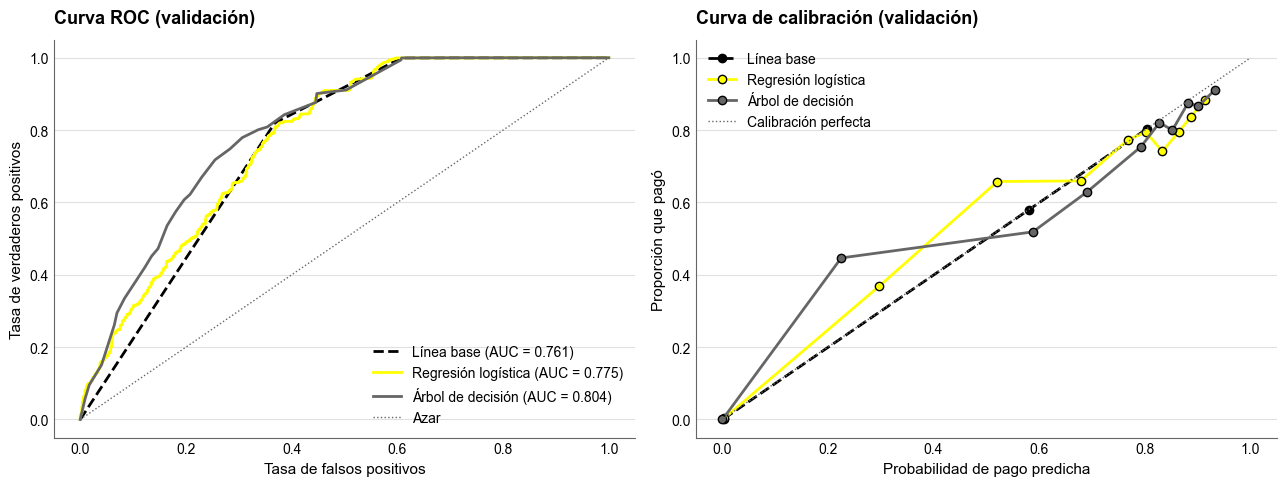

In [10]:
um.graficar_roc_calibracion(y_val, probabilidades_val, "(validación)")
plt.show()

**Interpretación.** Con la partición por dueño, los modelos mejoran poco sobre la línea base:

| | Línea base | Regresión logística | Árbol de decisión |
| --- | --- | --- | --- |
| Log-loss | 0,47 | 0,47 | 0,47 |
| ROC-AUC | 0,76 | 0,78 | 0,80 |
| F1 de "no paga" (umbral 0,5) | 0,56 | 0,59 | 0,64 |
| F1 de "no paga" (umbral que lo maximiza) | 0,64 | 0,64 | 0,66 |

Ordenan algo mejor (ROC-AUC) y detectan más predios que no pagarán con el umbral de 0,5: el árbol encuentra al 55 % de ellos, con 75 % de precisión, frente al 39 % de la línea base. Pero sus probabilidades no son mejores: el log-loss es el mismo.

Dentro de los grupos inciertos, la ganancia es pequeña:

- **Pagó 2025:** ROC-AUC de 0,56 con la logística y 0,64 con el árbol. Con el umbral de 0,5, ninguno señala casi a nadie: el árbol detecta menos del 1 % de los que dejan de pagar. Con el umbral que maximiza el F1, el del árbol en este grupo sube a 0,29.
- **Sin registro de 2025:** ROC-AUC de 0,52 y 0,56, apenas por encima del azar. El árbol señala al 66 % de los que no pagan, pero con solo 50 % de precisión.
- **Log-loss por grupo:** en los dos grupos los modelos quedan algo peor que la línea base (0,50 frente a 0,49 en pagó 2025; 0,70 y 0,72 frente a 0,68 sin registro). Lo que ganan en el total viene de ordenar mejor entre grupos, sobre todo a los dueños grandes.

En la calibración total, los modelos se apartan de la diagonal en el tramo bajo: donde el árbol predice 0,22, pagó el 45 %, y donde la logística predice 0,52, pagó el 66 %. La línea base, que solo usa tres probabilidades, queda sobre la diagonal.

La calibración dentro de los dos grupos donde el pago es incierto. El grupo que no pagó 2025 se omite: en validación tiene un solo pago. Con unos 600 a 1 900 predios por grupo se usan cinco intervalos; la línea base, que da la misma probabilidad a todo el grupo, es un solo punto.

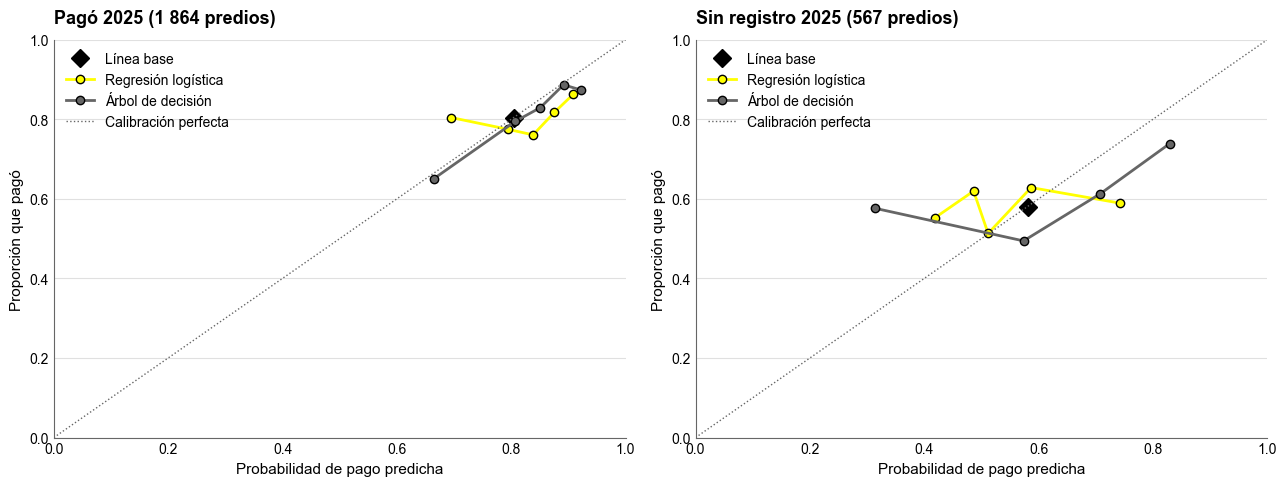

In [11]:
um.graficar_calibracion_por_grupo(validacion, probabilidades_val)
plt.show()

**Interpretación.**

- **Pagó 2025.** Los dos modelos quedan cerca de la diagonal, pero sus probabilidades se mueven en un rango estrecho (0,65 a 0,92): separan poco a los que dejan de pagar de los que no.
- **Sin registro de 2025.** Las curvas son casi planas: predigan 0,3 o 0,8, pagó entre el 49 % y el 74 %. Dentro de este grupo, los modelos casi no distinguen quién va a pagar, y la tasa del grupo (la línea base, 0,58) describe igual de bien a sus predios.

Para el recaudo esperado, las probabilidades de los modelos no son más confiables que las de la línea base.

#### Lectura de los modelos

- **Regresión logística:** los coeficientes de las variables estandarizadas, que se pueden comparar entre sí ([interpretar coeficientes](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/interpretar-coeficientes/)). Un coeficiente positivo sube la probabilidad de pagar.
- **Árbol:** sus primeros niveles, que son las reglas que más predios separan.
- **Los dos:** la importancia por permutación en validación, medida como cuánto empeora el log-loss al desordenar cada variable original. Permite comparar los dos modelos con la misma vara.

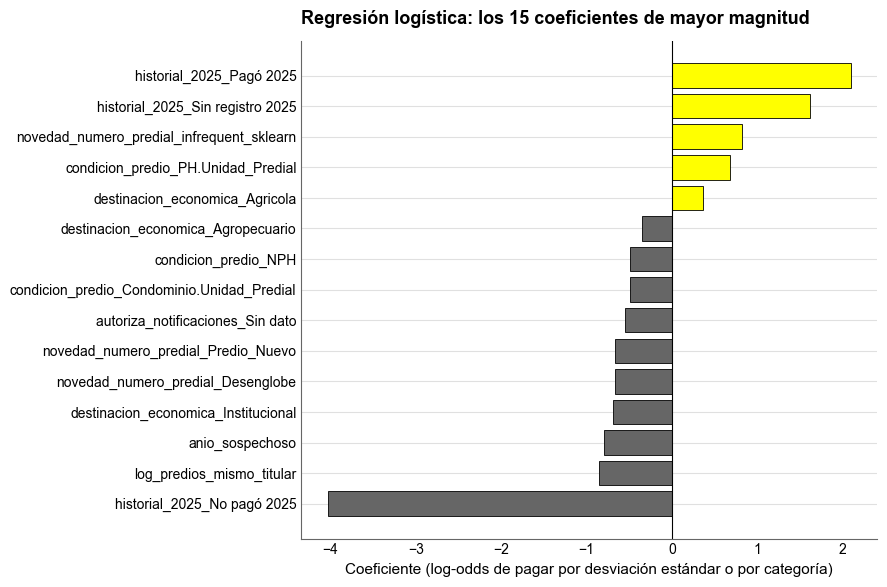

In [12]:
modelo_log = mejor_logistica.named_steps["modelo"]
nombres_log = mejor_logistica[:-1].get_feature_names_out()
coeficientes = pd.Series(modelo_log.coef_[0], index=nombres_log)
principales = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index[:15]).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([n.split("__", 1)[1] for n in principales.index],
        principales.values, color=[um.AMARILLO if v > 0 else um.GRIS for v in principales.values],
        edgecolor=um.NEGRO, linewidth=0.6)
ax.axvline(0, color=um.NEGRO, linewidth=0.8)
ax.set_xlabel("Coeficiente (log-odds de pagar por desviación estándar o por categoría)")
ax.set_title("Regresión logística: los 15 coeficientes de mayor magnitud")
plt.tight_layout(); plt.show()

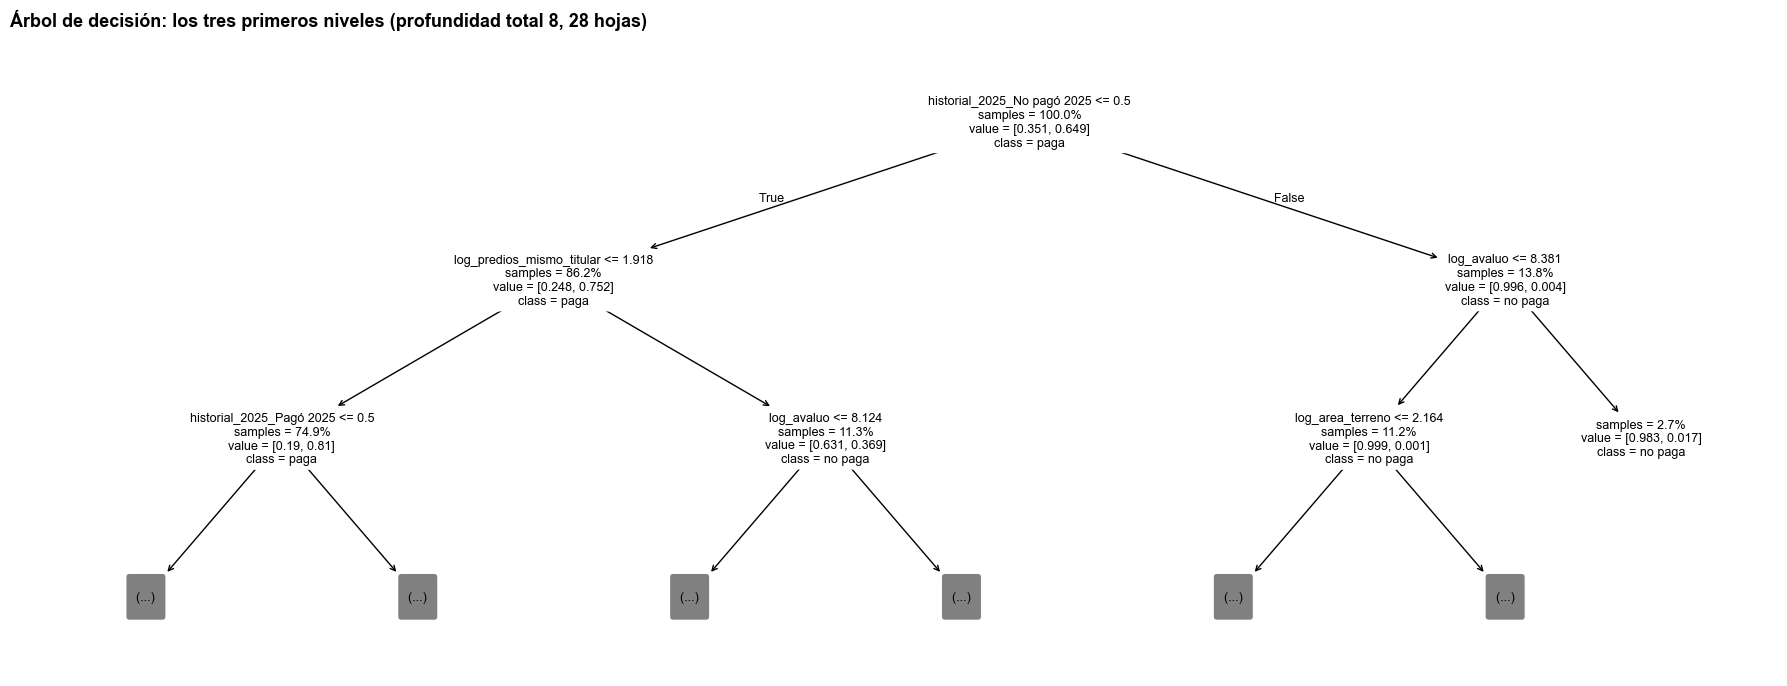

In [13]:
from sklearn.tree import plot_tree

arbol = mejor_arbol.named_steps["modelo"]
nombres_arbol = [n.split("__", 1)[1] for n in mejor_arbol[:-1].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arbol, max_depth=2, feature_names=nombres_arbol, class_names=["no paga", "paga"], filled=False,
          impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title(f"Árbol de decisión: los tres primeros niveles (profundidad total {arbol.get_depth()}, "
             f"{arbol.get_n_leaves()} hojas)")
plt.tight_layout(); plt.show()

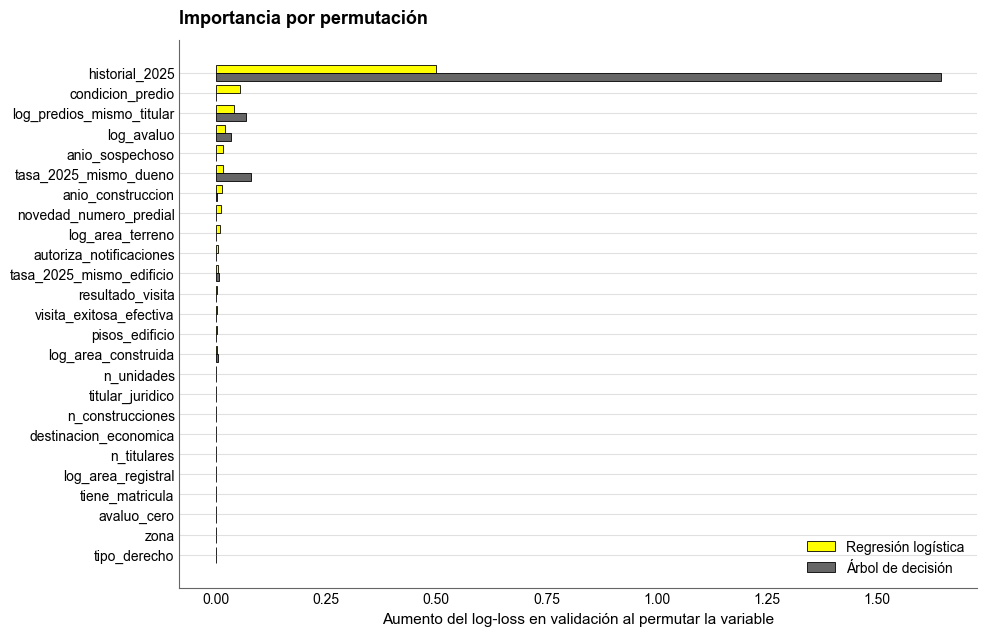

,Regresión logística,Árbol de decisión
historial_2025,0.50,1.64
condicion_predio,0.05,0.00
log_predios_mismo_titular,0.04,0.07
log_avaluo,0.02,0.04
anio_sospechoso,0.02,0.00
tasa_2025_mismo_dueno,0.02,0.08
anio_construccion,0.01,0.00
novedad_numero_predial,0.01,0.00
log_area_terreno,0.01,0.00
autoriza_notificaciones,0.01,0.00


In [14]:
from sklearn.inspection import permutation_importance

importancias = {}
for nombre, modelo in {"Regresión logística": mejor_logistica, "Árbol de decisión": mejor_arbol}.items():
    r = permutation_importance(modelo, X_val, y_val, scoring="neg_log_loss", n_repeats=5,
                               random_state=um.SEMILLA, n_jobs=1)
    importancias[nombre] = pd.Series(r.importances_mean, index=um.CARACTERISTICAS)
importancias = pd.DataFrame(importancias).sort_values("Regresión logística", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6.5))
y_pos = np.arange(len(importancias))[::-1]
ax.barh(y_pos + 0.2, importancias["Regresión logística"], height=0.4, color=um.AMARILLO, edgecolor=um.NEGRO,
        linewidth=0.6, label="Regresión logística")
ax.barh(y_pos - 0.2, importancias["Árbol de decisión"], height=0.4, color=um.GRIS, edgecolor=um.NEGRO,
        linewidth=0.6, label="Árbol de decisión")
ax.set_yticks(y_pos, importancias.index)
ax.set_xlabel("Aumento del log-loss en validación al permutar la variable")
ax.set_title("Importancia por permutación"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
importancias.head(10).round(4)

**Interpretación.**

- **Regresión logística.** Los coeficientes más grandes son del historial: no haber pagado 2025 baja los log-odds de pagar en 4,0 frente al promedio de las tres categorías, y haber pagado los sube en 2,1. Le siguen, con efectos mucho menores, la novedad del número predial (los predios nuevos y los desenglobes pagan menos), el número de predios del mismo titular (más predios, menos pago), el año de construcción de relleno y la condición del predio (la PH paga más que NPH y condominio). Como el one-hot no elimina ninguna categoría, cada coeficiente se lee frente al promedio de su variable.
- **Árbol.** El primer corte es el historial. Entre los que pagaron 2025 o no tienen registro, el segundo es el número de predios del mismo titular: los predios de dueños con más de 82 predios (11 % de entrenamiento) pagan el 37 %, frente al 81 % del resto. Después corta por avalúo y área de terreno.
- **Importancia por permutación.** En los dos modelos el historial es, con mucha distancia, lo que más pesa (0,50 y 1,64). Lo siguiente pesa diez veces menos o más: la condición del predio en la logística (0,05) y, en el árbol, la tasa de pago de 2025 de los otros predios del mismo dueño (0,08) y el número de predios del titular (0,07).

Con una evaluación que no deja reconocer dueños, la lectura se simplifica: el historial de pago decide casi todo, y las características del catastro solo agregan información sobre los dueños grandes y algo de orden dentro de los grupos.

#### Oportunidades de mejora de la regresión logística y el árbol


1. **Datos del comportamiento de pago.** Con una evaluación honesta, las características del catastro casi no distinguen quién paga dentro de cada historial. Lo que más ayudaría son datos que quedaron fuera del alcance: la fecha de pago, los pagos parciales, la cartera de años anteriores o el medio por el que se notificó al contribuyente.
2. **Un identificador anonimizado del dueño.** El sustituto actual (el número de predios del titular) no distingue a los dueños con menos de 10 predios y puede juntar a dos dueños con el mismo número. Con un identificador real se agruparía mejor la partición y se podría calcular el historial de cada dueño, que en el árbol ya es de lo poco que aporta.
3. **Confirmar la marca de pago de 2025 con Hacienda.** Si significa "sin deuda" y no "pagó 2025", el historial está en parte determinado por el pago de 2026 (etapa 3). Habría que redefinirlo con el estado al cierre de 2025.
4. **El impuesto facturado** quedó fuera por la sospecha de fuga (etapa 5 del notebook 08). Si Hacienda confirma qué valor registra la facturación, se podría usar el impuesto liquidado antes del pago.
5. **Validación cruzada por dueño.** Con dueños de cientos de predios, las métricas dependen de cuáles caen en validación. Repetir la evaluación con `StratifiedGroupKFold` daría una idea de esa variación antes de elegir.
6. **Calibración.** Las probabilidades de los dos modelos se apartan de la diagonal en el tramo bajo. Un ensamble (el *gradient boosting* de 4.3) o una calibración isotónica con `CalibratedClassifierCV` podrían corregirlo, lo que importa para el recaudo esperado.

### 4.3 Gradient boosting

Pendiente (issue #4): `HistGradientBoostingClassifier` en un pipeline con `um.crear_preprocesador(escalar=False)`, con la grilla evaluada con `evaluar_grilla` para que la tabla tenga las mismas columnas que las de 4.1 y 4.2.

In [15]:
# Pendiente: gradient boosting (por ejemplo, learning_rate, max_depth y max_iter)

### 4.4 Comparación y elección del modelo

Pendiente (issue #4): la tabla comparativa de los tres algoritmos y la línea base en validación (se puede extender `comparacion` y `probabilidades_val` con el *gradient boosting*), y la elección por log-loss.

In [16]:
# Pendiente: tabla comparativa en validación y elección del mejor modelo

<a id="cuantitativa"></a>

## 5. Evaluación cuantitativa

El modelo elegido, evaluado una sola vez en prueba, frente a la línea base y por grupo. El umbral que maximiza el F1 se eligió en validación, así que el F1 de validación con ese umbral es optimista: el de prueba es la cifra honesta.

In [17]:
# Pendiente: ROC-AUC, log-loss y curva de calibración en prueba

<a id="cualitativa"></a>

## 6. Evaluación cualitativa

Importancia de las variables (por permutación o coeficientes), ejemplos agregados de aciertos y errores, y si el comportamiento tiene sentido para el negocio.

In [18]:
# Pendiente: interpretación del modelo

<a id="recaudo"></a>

## 7. Del modelo al recaudo esperado

$R_{\text{esperado}} = \sum_i \mathit{IPU}_i\,p_i$: con el impuesto facturado en 2026 y las probabilidades del modelo en prueba, comparado con lo efectivamente pagado. Solo cifras agregadas.

**Advertencia.** El impuesto facturado quedó fuera de las características porque parece cambiar cuando el predio paga (etapa 5 del notebook 08). Si es así, compararlo con lo recaudado arrastra el mismo sesgo: conviene advertirlo al reportar, o usar el impuesto que calcula el motor de escenarios con las tarifas vigentes.

In [19]:
# Pendiente: recaudo esperado frente al observado, en prueba

<a id="mejora"></a>

## 8. Oportunidades de mejora

Pendiente: qué datos, variables o técnicas mejorarían el modelo.

<a id="guardar"></a>

## 9. Guardar el mejor modelo

El pipeline completo (transformaciones y modelo) en `entrega-2/producto/artefactos/modelo.joblib`, que no se sube al repositorio.

In [20]:
# Pendiente: um.CARPETA_ARTEFACTOS.mkdir(exist_ok=True); joblib.dump(mejor, um.ARCHIVO_MODELO)